# UNI2 ablation, cross-section (A0–A4)

Same split, same UNI2 class token (1536-d), same three heads. The only change between rows is the loss and the spatial block:

| | loss | spatial |
| --- | --- | --- |
| A0 | legacy: 3 CE + L2→L1 NLL weight 2 | none |
| A1 | adjacent: legacy NLL weight 1, plus NLL 0.5 / 0.5 and JS 0.1 / 0.1 | none |
| A2 | same as A1 | k=8 uniform mean of neighbor UNI2 vectors |
| A3 | same as A1 | same mean, multiplied by a learned gate |
| A4 | same as A1 | k=8 attention over neighbor UNI2 vectors |

The number to compare is the **pooled out-of-fold (OOF) L2 macro AUROC** in `validation_internal_metrics.csv` (the log line `OOF L2 macro AUROC=`). The last epoch's `Val head macro-AUROC` is only the inner validation of the last fold.

A4 finished with pooled OOF L2 **0.8780**. That is above A0 (0.8590) and A1 (0.8580), and below A2 (0.8884) and A3 (0.8907). A3 remains the pretrained weight.

- OOF（out-of-fold）：cross-section 五折里，每张切片只被留出一次。一个细胞的概率来自没见过它所在切片的那一折模型。5,627,071 个细胞各有一份这样的预测。
- pooled：这 562 万份预测先拼成一张表，再算一次 AUROC。A0 的这个数是 0.8590。五折各自的 L2 AUROC 再取平均是另一件事，A0 的折均值是 0.8458。折均值把五份切片子集看成同等重要；pooled 先按细胞放在一起，大折占的细胞更多。
- L2：最细的那一头，20 类（Tumor、CD8 T、Fibroblast、Neural 等）。L12 是 8 类，L1 是 5 类，都不是这个数。
- macro AUROC：每一类做一次 one-vs-rest AUROC，再对能算的类取算术平均。Neural 大约 1.1 万个细胞，Tumor 大约 84 万个，在这个平均里权重一样。某一类没有正例或没有负例时，这一类不进入平均。

Helpers live in `pred_statistic_visual.py`. The published UNI cross-section vs cross-celltype figures stay in `4_Pred_statistic_visual_pancancer_all.ipynb`.

The number to compare is the **pooled out-of-fold (OOF) L2 macro AUROC** in `validation_internal_metrics.csv` (the log line `OOF L2 macro AUROC=`). The last epoch's `Val head macro-AUROC` is only the inner validation of the last fold.

- OOF（out-of-fold）：cross-section 五折里，每张切片只被留出一次。一个细胞的概率来自没见过它所在切片的那一折模型。5,627,071 个细胞各有一份这样的预测。
- pooled：这 562 万份预测先拼成一张表，再算一次 AUROC。A0 的这个数是 0.8590。五折各自的 L2 AUROC 再取平均是另一件事，A0 的折均值是 0.8458。折均值把五份切片子集看成同等重要；pooled 先按细胞放在一起，大折占的细胞更多。
- L2：最细的那一头，20 类（Tumor、CD8 T、Fibroblast、Neural 等）。L12 是 8 类，L1 是 5 类，都不是这个数。
- macro AUROC：每一类做一次 one-vs-rest AUROC，再对能算的类取算术平均。Neural 大约 1.1 万个细胞，Tumor 大约 84 万个，在这个平均里权重一样。某一类没有正例或没有负例时，这一类不进入平均。

Helpers live in `pred_statistic_visual.py`. The published UNI cross-section vs cross-celltype figures stay in `4_Pred_statistic_visual_pancancer_all.ipynb`.


In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
PAN = REPO / "code" / "PanCancer"
if str(PAN) not in sys.path:
    sys.path.insert(0, str(PAN))


,arch,label,best_mlp,n_fold_ckpt,oof_npz,pooled_oof
0,A0,A0 legacy,True,5,True,True
1,A1,A1 adjacent,True,5,True,True
2,A2,A2 k8 mean,True,5,True,True
3,A3,A3 k8 mean+gate,True,5,True,True
4,A4,A4 k8 attention,True,5,True,True


,arch,label,n_cells,n_folds,best_fold,oof_l2_macro_auc,cv_l2_macro_f1_mean
0,A0,A0 legacy,5627071,5,0,0.858983,0.227990
1,A1,A1 adjacent,5627071,5,0,0.857994,0.230110
2,A2,A2 k8 mean,5627071,5,1,0.888378,0.301937
3,A3,A3 k8 mean+gate,5627071,5,0,0.890683,0.306338
4,A4,A4 k8 attention,5627071,5,0,0.877977,0.262741


Pooled OOF L2 macro AUROC  A0=0.8590  vs A0 +0.0000
Pooled OOF L2 macro AUROC  A1=0.8580  vs A0 -0.0010
Pooled OOF L2 macro AUROC  A2=0.8884  vs A0 +0.0294
Pooled OOF L2 macro AUROC  A3=0.8907  vs A0 +0.0317
Pooled OOF L2 macro AUROC  A4=0.8780  vs A0 +0.0190


,fold,A0_L2_auc,A0_L12_auc,A0_L1_auc,A0_sum_auc,A0_L2_f1,A0_L12_f1,A0_L1_f1,A0_best_epoch,A1_L2_auc,...,A3_L1_f1,A3_best_epoch,A4_L2_auc,A4_L12_auc,A4_L1_auc,A4_sum_auc,A4_L2_f1,A4_L12_f1,A4_L1_f1,A4_best_epoch
0,0,0.871416,0.809938,0.804932,2.486286,0.254000,0.333186,0.374803,13,0.873086,...,0.417701,9,0.889130,0.830132,0.822863,2.542125,0.280818,0.353406,0.387561,3
1,1,0.854479,0.792524,0.798196,2.445200,0.235960,0.326868,0.352320,11,0.855619,...,0.408249,10,0.875480,0.820100,0.823082,2.518661,0.261199,0.349842,0.372020,2
2,2,0.829531,0.786541,0.786496,2.402569,0.200765,0.317624,0.326849,12,0.829158,...,0.379225,10,0.849292,0.809191,0.809616,2.468099,0.230324,0.348566,0.357234,3
3,3,0.842159,0.784567,0.759689,2.386415,0.226971,0.394438,0.327683,8,0.842887,...,0.492268,12,0.859673,0.805217,0.781546,2.446436,0.271700,0.445227,0.346029,2
4,4,0.831441,0.770107,0.750462,2.352010,0.222256,0.340746,0.323151,12,0.831961,...,0.490473,13,0.856628,0.799192,0.777137,2.432957,0.269664,0.431587,0.328159,2


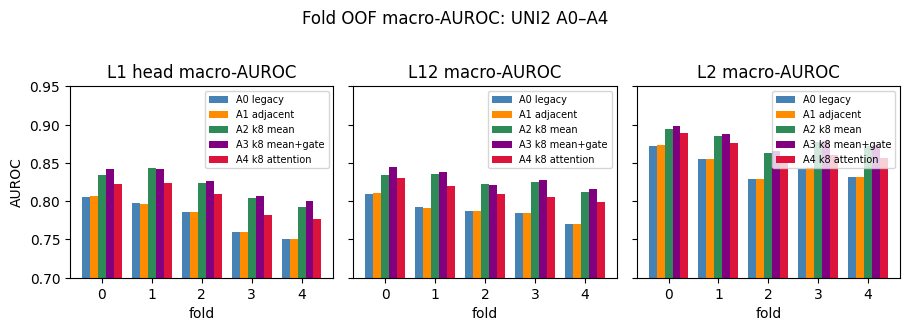

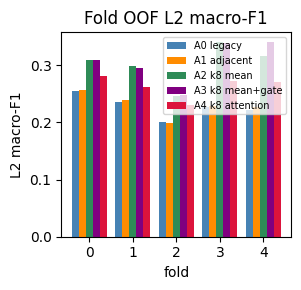

A0 missing roc_internal_level2_oof.pdf
A0 missing conf_matrix_level2.pdf
A1 missing roc_internal_level2_oof.pdf
A1 missing conf_matrix_level2.pdf
A2 missing roc_internal_level2_oof.pdf
A2 missing conf_matrix_level2.pdf
A3 missing roc_internal_level2_oof.pdf
A3 missing conf_matrix_level2.pdf
A4 missing roc_internal_level2_oof.pdf
A4 missing conf_matrix_level2.pdf


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from pred_statistic_visual import fold_csv, load_folds

PAN_DATA = REPO / "data" / "PanCancer"
OUT_AB = PAN_DATA / "uni2_ablation_compare"
OUT_AB.mkdir(parents=True, exist_ok=True)

ARCH = {
    "A0": {
        "label": "A0 legacy",
        "color": "steelblue",
        "result": PAN_DATA / "result_uni2_A0_legacy_nospatial",
        "tag": "A0_legacy_nospatial",
    },
    "A1": {
        "label": "A1 adjacent",
        "color": "darkorange",
        "result": PAN_DATA / "result_uni2_A1_adjacent_nospatial",
        "tag": "A1_adjacent_nospatial",
    },
    "A2": {
        "label": "A2 k8 mean",
        "color": "seagreen",
        "result": PAN_DATA / "result_uni2_A2_adjacent_spatial_k8mean",
        "tag": "A2_adjacent_spatial_k8mean",
    },
    "A3": {
        "label": "A3 k8 mean+gate",
        "color": "purple",
        "result": PAN_DATA / "result_uni2_A3_adjacent_spatial_k8mean_gate",
        "tag": "A3_adjacent_spatial_k8mean_gate",
    },
    "A4": {
        "label": "A4 k8 attention",
        "color": "crimson",
        "result": PAN_DATA / "result_uni2_A4_adjacent_spatial_k8attention",
        "tag": "A4_adjacent_spatial_k8attention",
    },
}


ready = []
inv_rows = []
for key, spec in ARCH.items():
    ckpt = spec["result"] / "cross_dataset_cv" / spec["tag"]
    metrics_path = spec["result"] / "validation_internal_metrics.csv"
    fold_path = fold_csv(spec)
    has_oof = metrics_path.is_file() and fold_path.is_file()
    inv_rows.append(
        {
            "arch": key,
            "label": spec["label"],
            "best_mlp": (ckpt / "best_mlp_gpu.pt").is_file(),
            "n_fold_ckpt": len(list(ckpt.glob("hce_group_fold_[0-9].pt"))),
            "oof_npz": (spec["result"] / "oof_predictions.npz").is_file(),
            "pooled_oof": has_oof,
        }
    )
    if has_oof:
        ready.append(key)
    else:
        print(f"{key}: pooled OOF not written yet ({metrics_path.name})")
display(pd.DataFrame(inv_rows))
if not ready:
    raise FileNotFoundError("No finished UNI2 OOF result under data/PanCancer/result_uni2_A*")

oof_rows = []
for key in ready:
    row = pd.read_csv(ARCH[key]["result"] / "validation_internal_metrics.csv").iloc[0].to_dict()
    row["arch"] = key
    row["label"] = ARCH[key]["label"]
    oof_rows.append(row)
oof_sum = pd.DataFrame(oof_rows)
cols = [c for c in ("arch", "label", "n_cells", "n_folds", "best_fold", "oof_l2_macro_auc", "cv_l2_macro_f1_mean") if c in oof_sum]
display(oof_sum[cols])
base = float(oof_sum.loc[oof_sum.arch == "A0", "oof_l2_macro_auc"].iloc[0])
for _, row in oof_sum.iterrows():
    print(f"Pooled OOF L2 macro AUROC  {row.arch}={float(row.oof_l2_macro_auc):.4f}  vs A0 {float(row.oof_l2_macro_auc) - base:+.4f}")

folds = load_folds(fold_csv(ARCH[ready[0]]), ready[0])
for key in ready[1:]:
    folds = folds.join(load_folds(fold_csv(ARCH[key]), key))
folds = folds.reset_index()
display(folds)

n_arch = len(ready)
width = 0.8 / n_arch
fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.2), sharey=True)
for ax, metric, title in (
    (axes[0], "L1_auc", "L1 head"),
    (axes[1], "L12_auc", "L12"),
    (axes[2], "L2_auc", "L2"),
):
    x = folds["fold"].to_numpy()
    for i, key in enumerate(ready):
        ax.bar(
            x + (i - (n_arch - 1) / 2) * width,
            folds[f"{key}_{metric}"],
            width=width,
            label=ARCH[key]["label"],
            color=ARCH[key]["color"],
        )
    ax.set_title(f"{title} macro-AUROC")
    ax.set_xlabel("fold")
    ax.set_xticks(list(range(5)))
    ax.set_ylim(0.7, 0.95)
    ax.legend(fontsize=7)
axes[0].set_ylabel("AUROC")
fig.suptitle("Fold OOF macro-AUROC: UNI2 A0–A4", y=1.02)
fig.tight_layout()
fig.savefig(OUT_AB / "fold_oof_auroc_A0_A4.pdf", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(3.2, 3.0))
x = folds["fold"].to_numpy()
for i, key in enumerate(ready):
    ax.bar(
        x + (i - (n_arch - 1) / 2) * width,
        folds[f"{key}_L2_f1"],
        width=width,
        label=ARCH[key]["label"],
        color=ARCH[key]["color"],
    )
ax.set_xticks(list(range(5)))
ax.set_xlabel("fold")
ax.set_ylabel("L2 macro-F1")
ax.set_title("Fold OOF L2 macro-F1")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT_AB / "fold_oof_l2_f1_A0_A4.pdf", dpi=150, bbox_inches="tight")
plt.show()

for key in ready:
    spec = ARCH[key]
    for title, name in (("OOF L2 ROC", "roc_internal_level2_oof.pdf"), ("OOF L2 confusion", "conf_matrix_level2.pdf")):
        path = spec["result"] / name
        if not path.is_file():
            print(f"{key} missing {name}")
            continue
        print(f"{key} {title}", path)
        display(Image(filename=str(path), width=480))


Loaded cached A0 OOF tables
Loaded cached A1 OOF tables
Loaded cached A2 OOF tables
Loaded cached A3 OOF tables
Scoring A4 OOF probabilities …
Wrote /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/uni2_ablation_compare/oof_per_class_A4.csv


arch,dataset,head,A0,A1,A2,A3,A4,A1_minus_A0,A2_minus_A0,A3_minus_A0,A4_minus_A0
0,BRCA,L1,0.783200,0.784466,0.824778,0.829077,0.808742,0.001266,0.041578,0.045877,0.025542
1,BRCA,L12,0.810014,0.810314,0.838816,0.844014,0.831860,0.000300,0.028802,0.034000,0.021846
2,BRCA,L2,0.788801,0.789257,0.824102,0.826031,0.808630,0.000456,0.035300,0.037230,0.019829
3,CRC,L1,0.727947,0.728169,0.786315,0.790121,0.761160,0.000222,0.058368,0.062174,0.033213
4,CRC,L12,0.730289,0.731259,0.792508,0.793645,0.768516,0.000971,0.062219,0.063357,0.038227
5,CRC,L2,0.772104,0.773073,0.835744,0.837804,0.813170,0.000969,0.063640,0.065700,0.041066
6,GBM,L1,0.678560,0.675947,0.763957,0.769780,0.730862,-0.002613,0.085397,0.091220,0.052303
7,GBM,L12,0.667937,0.665689,0.745775,0.750255,0.717527,-0.002248,0.077838,0.082318,0.049591
8,GBM,L2,0.694586,0.694471,0.764203,0.766578,0.738424,-0.000115,0.069616,0.071992,0.043838
9,GIST,L1,0.756201,0.756793,0.799141,0.804380,0.779270,0.000592,0.042939,0.048179,0.023069


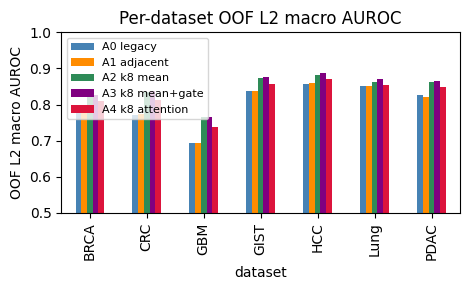


=== L2 per-class OOF AUROC  macro A0=0.8590  A1=0.8580  A2=0.8884  A3=0.8907  A4=0.8780 ===


,class_name,n_pos_A0,auroc_A0,auroc_A1,auroc_A2,auroc_A3,auroc_A4,A1_minus_A0,A2_minus_A0,A3_minus_A0,A4_minus_A0
10,B_cell,135794,0.729440,0.732836,0.788168,0.801454,0.803498,0.003396,0.058728,0.072013,0.074057
3,Epithelial,556973,0.814997,0.814973,0.883392,0.883155,0.859012,-0.000023,0.068395,0.068159,0.044015
11,Plasma,61271,0.819366,0.823255,0.866667,0.869813,0.846816,0.003889,0.047301,0.050447,0.027450
12,DC,316538,0.786044,0.786397,0.830094,0.831912,0.815754,0.000354,0.044050,0.045869,0.029710
6,CD4_T,454922,0.774569,0.774725,0.813322,0.818863,0.791765,0.000156,0.038754,0.044294,0.017197
18,Endothelial,445047,0.721956,0.718747,0.755759,0.765007,0.741323,-0.003209,0.033803,0.043051,0.019368
7,CD8_T,426920,0.869937,0.868320,0.907967,0.911929,0.886794,-0.001618,0.038030,0.041992,0.016856
13,Macrophage,686418,0.679188,0.686881,0.711095,0.719361,0.688622,0.007693,0.031907,0.040174,0.009435
8,Tregs,322139,0.869067,0.868539,0.906672,0.907535,0.888882,-0.000528,0.037605,0.038468,0.019814
15,Fibroblast,851747,0.776866,0.776997,0.810625,0.812687,0.794276,0.000131,0.033759,0.035821,0.017411


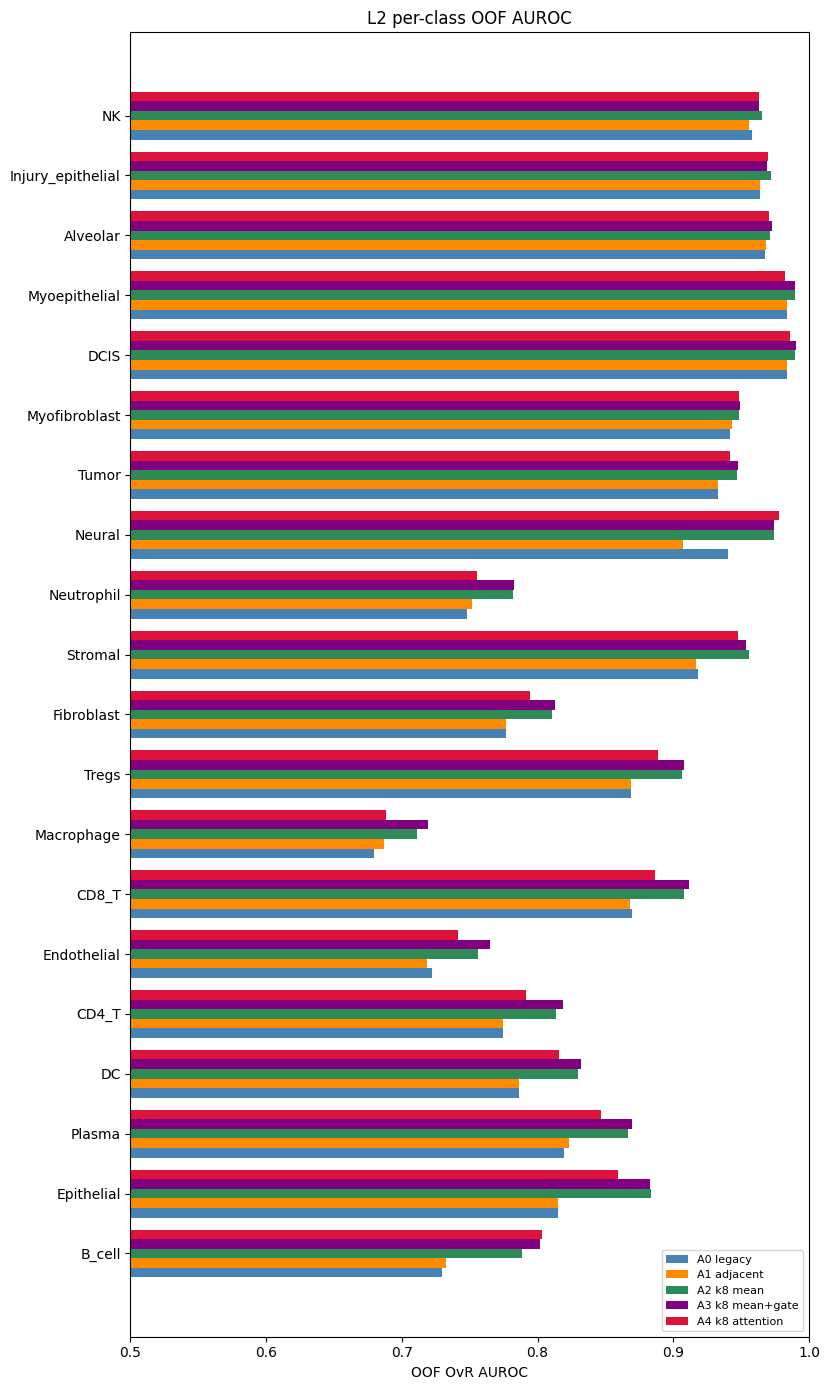


=== L12 per-class OOF AUROC  macro A0=0.7967  A1=0.7923  A2=0.8342  A3=0.8385  A4=0.8238 ===


,class_name,n_pos_A0,auroc_A0,auroc_A1,auroc_A2,auroc_A3,auroc_A4,A1_minus_A0,A2_minus_A0,A3_minus_A0,A4_minus_A0
1,Epithelial,647123,0.803715,0.805227,0.869344,0.868365,0.845610,0.001512,0.065629,0.064650,0.041895
3,B_Plasma,197065,0.739125,0.739258,0.785754,0.798767,0.790276,0.000134,0.046629,0.059642,0.051151
7,Neural,10848,0.922439,0.886299,0.971244,0.968969,0.970169,-0.036140,0.048805,0.046530,0.047730
6,Endothelial,445047,0.736253,0.735555,0.771871,0.779619,0.753317,-0.000698,0.035618,0.043366,0.017065
5,Stromal,1048592,0.746365,0.746737,0.783261,0.788121,0.769714,0.000372,0.036896,0.041756,0.023349
4,Myeloid,1180381,0.687824,0.688079,0.719306,0.723429,0.701398,0.000254,0.031482,0.035605,0.013574
2,T_cell,1215636,0.794933,0.795182,0.819606,0.825515,0.807104,0.000249,0.024673,0.030582,0.012172
0,Tumor,882379,0.943073,0.942259,0.953553,0.955135,0.953101,-0.000813,0.010480,0.012062,0.010028


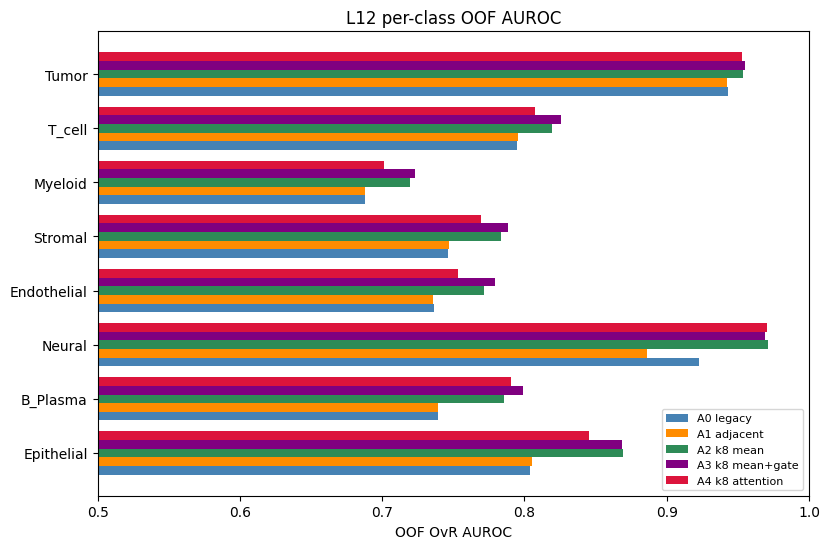


=== L1 per-class OOF AUROC  macro A0=0.7967  A1=0.7901  A2=0.8373  A3=0.8404  A4=0.8215 ===


,class_name,n_pos_A0,auroc_A0,auroc_A1,auroc_A2,auroc_A3,auroc_A4,A1_minus_A0,A2_minus_A0,A3_minus_A0,A4_minus_A0
0,Epithelial,1529502,0.824686,0.823632,0.871231,0.875478,0.840220,-0.001054,0.046544,0.050791,0.015533
4,Neural,10848,0.925798,0.893503,0.971955,0.969425,0.976122,-0.032295,0.046156,0.043627,0.050324
3,Endothelial,445047,0.732750,0.731292,0.770510,0.776363,0.750629,-0.001458,0.037760,0.043612,0.017878
2,Stromal,1048592,0.740058,0.740731,0.779696,0.782449,0.764009,0.000672,0.039638,0.042390,0.023951
1,Immune,2593082,0.760454,0.761333,0.793245,0.798328,0.776321,0.000879,0.032792,0.037875,0.015868


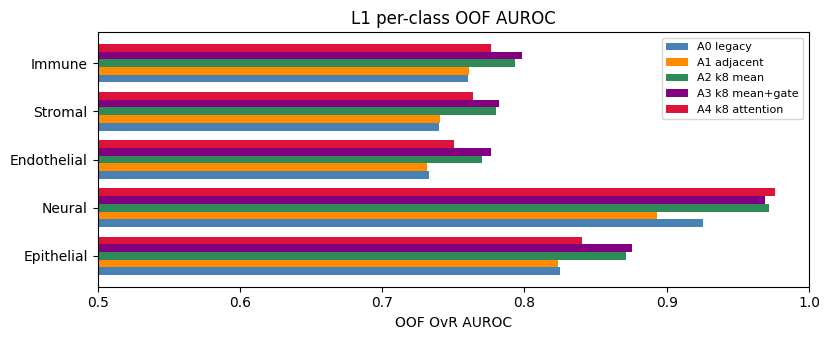

In [3]:
import numpy as np

from pred_statistic_visual import load_ontology_heads, oof_labels, oof_tables, split_old_cache

CLASS_NAMES = load_ontology_heads(PAN_DATA / "ontology_heads.json")

split_old_cache(OUT_AB)
scored = [key for key, spec in ARCH.items() if (spec["result"] / "oof_predictions.npz").is_file()]
missing = [key for key in ARCH if key not in scored]
if missing:
    print("No oof_predictions.npz yet:", ", ".join(missing))
if "A0" not in scored:
    raise FileNotFoundError("A0 oof_predictions.npz is required as the label reference")
ref_labels = oof_labels(ARCH["A0"])
class_parts, dataset_parts = [], []
for key in scored:
    spec = ARCH[key]
    if key != "A0" and not np.array_equal(ref_labels, oof_labels(spec)):
        raise ValueError(f"{key} OOF L2 labels differ from A0; refuse to compare different cells")
    class_path = OUT_AB / f"oof_per_class_{key}.csv"
    dataset_path = OUT_AB / f"oof_per_dataset_{key}.csv"
    if class_path.is_file() and dataset_path.is_file():
        classes_df = pd.read_csv(class_path)
        dataset_df = pd.read_csv(dataset_path)
        print(f"Loaded cached {key} OOF tables")
    else:
        print(f"Scoring {key} OOF probabilities …", flush=True)
        classes_df, dataset_df = oof_tables(spec, CLASS_NAMES)
        classes_df.to_csv(class_path, index=False)
        dataset_df.to_csv(dataset_path, index=False)
        print(f"Wrote {class_path}")
    classes_df = classes_df.copy()
    dataset_df = dataset_df.copy()
    classes_df.insert(0, "arch", key)
    dataset_df.insert(0, "arch", key)
    class_parts.append(classes_df)
    dataset_parts.append(dataset_df)

per_class = pd.concat(class_parts, ignore_index=True)
per_dataset = pd.concat(dataset_parts, ignore_index=True)
per_class.to_csv(OUT_AB / "oof_per_class_auroc.csv", index=False)
per_dataset.to_csv(OUT_AB / "oof_per_dataset_auroc.csv", index=False)

wide_ds = per_dataset.pivot_table(index=["dataset", "head"], columns="arch", values="macro_auroc")
for key in scored:
    if key == "A0":
        continue
    wide_ds[f"{key}_minus_A0"] = wide_ds[key] - wide_ds["A0"]
wide_ds = wide_ds.reset_index()
display(wide_ds)

l2_ds = wide_ds.loc[wide_ds["head"] == "L2"].set_index("dataset")
ax = l2_ds[scored].plot(kind="bar", figsize=(4.8, 3.0), color=[ARCH[k]["color"] for k in scored])
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("OOF L2 macro AUROC")
ax.set_title("Per-dataset OOF L2 macro AUROC")
ax.legend([ARCH[k]["label"] for k in scored], fontsize=8)
plt.tight_layout()
fig = ax.get_figure()
fig.savefig(OUT_AB / "dataset_oof_l2_auroc_A0_A4.pdf", dpi=150, bbox_inches="tight")
plt.show()

for head in ("L2", "L12", "L1"):
    parts = []
    for key in scored:
        sub = per_class.loc[(per_class["arch"] == key) & (per_class["head"] == head), ["class_name", "n_pos", "auroc"]]
        sub = sub.rename(columns={"auroc": f"auroc_{key}", "n_pos": f"n_pos_{key}"})
        parts.append(sub)
    m = parts[0]
    for sub in parts[1:]:
        m = m.merge(sub.drop(columns=[c for c in sub.columns if c.startswith("n_pos_")]), on="class_name")
    for key in scored:
        if key == "A0":
            continue
        m[f"{key}_minus_A0"] = m[f"auroc_{key}"] - m["auroc_A0"]
    sort_col = "A3_minus_A0" if "A3_minus_A0" in m.columns else "auroc_A0"
    m = m.sort_values(sort_col, ascending=False)
    macros = "  ".join(f"{key}={m[f'auroc_{key}'].mean():.4f}" for key in scored)
    print(f"\n=== {head} per-class OOF AUROC  macro {macros} ===")
    display(m)
    fig, ax = plt.subplots(figsize=(8.4, max(3.4, 0.28 * len(m) * max(1, len(scored) / 2))))
    y = np.arange(len(m))
    height = 0.8 / len(scored)
    for i, key in enumerate(scored):
        ax.barh(
            y + (i - (len(scored) - 1) / 2) * height,
            m[f"auroc_{key}"],
            height=height,
            label=ARCH[key]["label"],
            color=ARCH[key]["color"],
        )
    ax.set_yticks(y, m["class_name"])
    ax.set_xlim(0.5, 1.0)
    ax.set_xlabel("OOF OvR AUROC")
    ax.set_title(f"{head} per-class OOF AUROC")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT_AB / f"per_class_{head.lower()}_auroc_A0_A4.pdf", dpi=150, bbox_inches="tight")
    plt.show()
